In [177]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ========= 修改为你自己的学号 =========
STUDENT_ID = 20244080113


CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]        {STUDENT_ID}")
print(f"[机器指纹]    {MACHINE_FP}")
print(f"[RUN_ID]     {RUN_ID}")


[Conda 环境] py_exp01
[学号]        20244080113
[机器指纹]    f6664b7564c935dd
[RUN_ID]     20244080113-f6664b7564c935dd


In [178]:
# 任务1：整数、浮点、布尔ndarray，打印dtype/shape/ndim 
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1,2.2,3.3])
arr_bool = np.array([True, False, True])

print("整数数组")
print("数组：", arr_int)
print("dtype：", arr_int.dtype)
print("shape：", arr_int.shape)
print("ndim：", arr_int.ndim)

print("\n浮点数数组 ")
print("数组：", arr_float)
print("dtype：", arr_float.dtype)
print("shape：", arr_float.shape)
print("ndim：", arr_float.ndim)

print("\n布尔数组 ")
print("数组：", arr_bool)
print("dtype：", arr_bool.dtype)
print("shape：", arr_bool.shape)
print("ndim：", arr_bool.ndim)


整数数组
数组： [1 2 3 4]
dtype： int64
shape： (4,)
ndim： 1

浮点数数组 
数组： [1.1 2.2 3.3]
dtype： float64
shape： (3,)
ndim： 1

布尔数组 
数组： [ True False  True]
dtype： bool
shape： (3,)
ndim： 1


解释：NumPy数组所有元素必须是同一种数据类型；Python列表可以存放不同类型的数据

In [179]:
# 任务2：reshape改变形状
a = np.arange(12)
print("\n原始数组 np.arange(12) ")
print(a)

a1 = a.reshape(3,4)
print("\nreshape(3,4):")
print(a1)

a2 = a.reshape(2,3,2)
print("\nreshape(2,3,2):")
print(a2)


原始数组 np.arange(12) 
[ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


解释：改变数组形状时，新shape所有维度相乘 = 原数组元素总数

In [180]:
#任务3：数组索引（3,4）数组 
arr_34 = np.arange(12).reshape(3,4)
print("\n 形状(3,4)数组 ")
print(arr_34)

row2 = arr_34[1,:]   # 第2行，下标从0开始
col1_3 = arr_34[:,0:3] # 第1到3列
gt6 = arr_34[arr_34>6]

print("\n取第2行：")
print(row2, " shape=", row2.shape)
print("\n取第1至第3列：")
print(col1_3, " shape=", col1_3.shape)
print("\n大于6的元素：")
print(gt6, " shape=", gt6.shape)


 形状(3,4)数组 
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行：
[4 5 6 7]  shape= (4,)

取第1至第3列：
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]  shape= (3, 3)

大于6的元素：
[ 7  8  9 10 11]  shape= (5,)


In [181]:
#  任务4 np.arange(10)
b = np.arange(10)
print("\nnp.arange(10) ")
print(b)

res_or = b[(b<2) | (b>7)]
res_and = b[(b>3) & (b<7)]
# 等价写法：np.logical_or(b<2, b>7) 、np.logical_and(b>3,b<7)
res_or2 = b[np.logical_or(b<2, b>7)]
res_and2 = b[np.logical_and(b>3,b<7)]

print("\n小于2或大于7：", res_or)
print("小于2或大于7（logical_or）：", res_or2)
print("\n大于3且小于7：", res_and)
print("大于3且小于7（logical_and）：", res_and2)


np.arange(10) 
[0 1 2 3 4 5 6 7 8 9]

小于2或大于7： [0 1 8 9]
小于2或大于7（logical_or）： [0 1 8 9]

大于3且小于7： [4 5 6]
大于3且小于7（logical_and）： [4 5 6]


In [182]:
# 任务5 逐元素乘法与矩阵乘法
m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
print("\n两个(2,2)数组 ")
print("m1:\n", m1)
print("m2:\n", m2)

elem_mul = m1 * m2
elem_mul2 = np.multiply(m1,m2)
mat_mul = m1 @ m2
mat_mul2 = np.matmul(m1,m2)

print("\n逐元素乘法 m1*m2：")
print(elem_mul)
print("\nnp.multiply()：")
print(elem_mul2)

print("\n矩阵乘法 m1 @ m2 ：")
print(mat_mul)
print("\nnp.matmul()：")
print(mat_mul2)


两个(2,2)数组 
m1:
 [[1 2]
 [3 4]]
m2:
 [[5 6]
 [7 8]]

逐元素乘法 m1*m2：
[[ 5 12]
 [21 32]]

np.multiply()：
[[ 5 12]
 [21 32]]

矩阵乘法 m1 @ m2 ：
[[19 22]
 [43 50]]

np.matmul()：
[[19 22]
 [43 50]]


逐元素乘法：两个数组相同位置的元素一对一相乘，不要求满足矩阵乘法的行列匹配规则，只要求两个数组形状一致，结果数组形状和输入相同。
矩阵乘法：第一个矩阵的列数必须等于第二个矩阵的行数，结果矩阵的形状为第一个矩阵的行数和第二个矩阵的列数。结果矩阵第i行第j列的值，是第一个矩阵第i行和第二个矩阵第j列对应元素相乘再求和


In [183]:
np.random.seed(40)
#任务1：生成正态分布成绩 
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
n = len(scores)
min_s = scores.min()
max_s = scores.max()
mean_s = scores.mean()
std_s = scores.std()
range_s = max_s - min_s

print("任务1 模拟成绩统计")
print(f"样本数：{n}")
print(f"最小值：{min_s:.2f}")
print(f"最大值：{max_s:.2f}")
print(f"均值：{mean_s:.2f}")
print(f"标准差：{std_s:.2f}")
print(f"极差：{range_s:.2f}")

任务1 模拟成绩统计
样本数：1000
最小值：38.15
最大值：100.00
均值：70.46
标准差：9.92
极差：61.85


关于最后标准差不是10：使用np.random.normal指定分布参数均值 70、标准差 10 生成样本后，np.clip截断会剔除极端值，压缩数据范围，把超过 100、低于 0 的极端值强行砍掉，数据被截断，离散程度变小，样本标准差就不再是原始设定的 10 了。

In [184]:
#任务2：不放回抽样：均匀抽样和加权抽样 
arr = np.arange(1,11)
# 均匀不放回抽样，每个数概率相等
sample_uniform = np.random.choice(arr, size=5, replace=False)
# 按整数大小加权：权重=自身数值
p_weight = arr / arr.sum()
sample_weighted = np.random.choice(arr, size=5, replace=False, p=p_weight)

print("\n任务2 抽样对比")
print("原数组：", arr)
print("均匀不放回抽样：", sample_uniform)
print("加权抽样，权重等于数值大小：", sample_weighted)



任务2 抽样对比
原数组： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [7 2 5 3 9]
加权抽样，权重等于数值大小： [10  7  3  6  9]


比较：均匀抽样每个元素抽取概率相同；加权抽样数值越大，被抽到概率越高。

In [185]:
#任务3：随机排列保留原数组和原地打乱区别
data = np.array([1,2,3,4,5,6])
data_copy = data.copy()
# 方式1：返回新数组，原数组不变
shuffle_new = np.random.permutation(data)
# 方式2：原地打乱，修改原始数组
np.random.shuffle(data_copy)

print("\n任务3 随机排列对比")
print("原始数组：", data)
print("生成新数组，原数组不变：", shuffle_new)
print("原地打乱后的数组：", data_copy)



任务3 随机排列对比
原始数组： [1 2 3 4 5 6]
生成新数组，原数组不变： [5 1 3 4 2 6]
原地打乱后的数组： [4 6 3 2 5 1]


保留原数组：复制一份数据做打乱，返回新的打乱后的数组，原始数组不被修改。适合需要同时保留原始顺序和打乱版本的场景。
原地打乱：直接在原来的内存位置打乱元素，原数组本身被改变，没有返回值。节省内存，但原始顺序直接丢失。

In [186]:
# 任务4：设置nan缺失值，对比均值
scores_nan = scores.copy()
# 第10、20、30个（下标9,19,29）设为nan
scores_nan[[9,19,29]] = np.nan
mean_normal = np.mean(scores_nan)       #普通求均值，遇到nan直接返回nan
mean_nanignore = np.nanmean(scores_nan) #忽略缺失值求均值
nan_count = np.isnan(scores_nan).sum()
print("\n任务4 缺失值对比")
print(f"缺失值个数：{nan_count}")
print(f"普通求均值结果：{mean_normal}")
print(f"忽略缺失值均值：{mean_nanignore:.2f}")
print("下标9,19,29原来的成绩：", scores[[9,19,29]])


任务4 缺失值对比
缺失值个数：3
普通求均值结果：nan
忽略缺失值均值：70.45
下标9,19,29原来的成绩： [80.55534443 57.25016393 83.71408787]


普通求均值结果是nan原因：普通统计函数碰到nan会直接返回nan; 
nan对普通统计函数影响：nan系列函数会跳过缺失值计算均值

In [187]:
# 任务5：构造表格pandas，只在内存，不写入磁盘
index_arr = np.arange(len(scores_nan))  # 序号
df_score = pd.DataFrame({
    "序号": index_arr,
    "成绩": scores_nan
})
print("\n任务5 预览表格前20行")
print(df_score.head(20))


任务5 预览表格前20行
    序号         成绩
0    0  63.924523
1    1  68.738636
2    2  63.153936
3    3  79.287147
4    4  51.555990
5    5  65.329976
6    6  92.924903
7    7  74.888101
8    8  77.102670
9    9        NaN
10  10  70.540731
11  11  72.579534
12  12  75.882816
13  13  78.852442
14  14  59.829930
15  15  68.663070
16  16  65.618145
17  17  74.934435
18  18  68.009909
19  19        NaN


In [188]:
import numpy as np
from scipy import linalg, optimize, stats
import matplotlib.pyplot as plt

# 任务1：解线性方程组 3x+y=9，x+2y=8 
A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])
sol = linalg.solve(A, b)
x, y = sol[0], sol[1]
print("任务1")
print(f"方程组解：x={x:.2f}, y={y:.2f}")
# 代入验证
print("代入验证 ：", A @ sol)

任务1
方程组解：x=2.00, y=3.00
代入验证 ： [9. 8.]


In [189]:
#任务2：root求 x²-2=0 的正负根 
def f(x):
    return x**2 - 2

# 正根：初始猜测 2
root_pos = optimize.root(f, x0=2)
# 负根：初始猜测 -2
root_neg = optimize.root(f, x0=-2)

val_pos = f(root_pos.x)
val_neg = f(root_neg.x)

print("\n任务2")
print("正根求解：", root_pos.success, " 结果：", root_pos.x)
print("正根函数值是否接近0：", np.isclose(val_pos, 0))
print("负根求解：", root_neg.success, " 结果：", root_neg.x )
print("负根函数值是否接近0：", np.isclose(val_neg, 0))


任务2
正根求解： True  结果： [1.41421356]
正根函数值是否接近0： [ True]
负根求解： True  结果： [-1.41421356]
负根函数值是否接近0： [ True]


In [190]:
# 任务3：minimize 求 f(x)=x²+x+2 最小值 
def func_min(x):
    return x**2 + x + 2
# 解析解：导数 2x+1=0 → x=-0.5，f(-0.5)=1.75
res_min = optimize.minimize(func_min, x0=0)
print("\n任务3")
print("极小点 x =", res_min.x[0])
print("极小函数值 =", res_min.fun)
print("解析结果：x=-0.5，最小值=1.75")


任务3
极小点 x = -0.5000000064345924
极小函数值 = 1.75
解析结果：x=-0.5，最小值=1.75


解析结果的极小点 x=-0.5，最小值=1.75，是近似值，但是数学函数算出来的是精确值有具体小数点后几位

In [191]:
# 任务4：独立样本t检验 
np.random.seed(10)  # 固定随机种子
s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_val = stats.ttest_ind(s1, s2)
print("\n任务4")
print(f"t统计量：{t_stat:.4f}，p值：{p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p < {alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p ≥ {alpha}，不能拒绝原假设，无显著差异")


任务4
t统计量：-7.1333，p值：0.0000
p < 0.05，拒绝原假设，两组均值存在显著差异


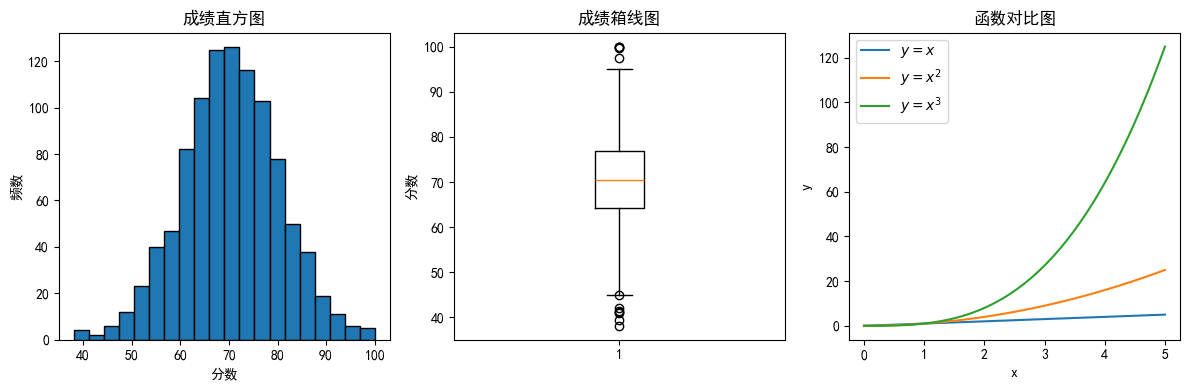

In [192]:
# 任务5：Matplotlib绘图 
import numpy as np
import matplotlib.pyplot as plt

# 从实验2的表格里取出成绩列，过滤nan得到有效成绩
scores_valid = df_score["成绩"].dropna()

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.hist(scores_valid, bins=20, edgecolor="black")
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,3,2)
plt.boxplot(scores_valid)
plt.title("成绩箱线图")
plt.ylabel("分数")

plt.subplot(1,3,3)
x_line = np.linspace(0,5,100)
y1 = x_line
y2 = x_line**2
y3 = x_line**3
plt.plot(x_line, y1, label="$y=x$")
plt.plot(x_line, y2, label="$y=x^2$")
plt.plot(x_line, y3, label="$y=x^3$")
plt.title("函数对比图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.tight_layout()
plt.show()

In [193]:
import pandas as pd
import numpy as np

# 任务1 创建 DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")  # 行索引设为姓名
# 计算总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("任务1")
print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

任务1
行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [194]:
# 任务2 ⽤ loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学⽣
print("\n 任务2 ")
print("loc读取Carol（Carol第2行，下标2）：")
print(df.loc["Carol"])
print("\niloc读取Carol（Carol第2行，下标2）：")
print(df.iloc[2])
print("\n平均分不低于80的学生：")
print(df[df["Average"] >= 80])


 任务2 
loc读取Carol（Carol第2行，下标2）：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc读取Carol（Carol第2行，下标2）：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于80的学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [195]:
# 任务3 计算三科成绩的列均值和每名学⽣的⾏均值
print("\n 任务3 ")
print("mean(axis=0) 各科列均值：")
res0 = df[["Math","English","Python"]].mean(axis=0)
print(res0.to_string(dtype=False))
print("\nmean(axis=1) 每个学生行均值：")
res1 = df[["Math","English","Python"]].mean(axis=1)
print(res1.to_string(dtype=False))


 任务3 
mean(axis=0) 各科列均值：
Math       79.833333
English    80.833333
Python     83.666667

mean(axis=1) 每个学生行均值：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000


In [196]:
# 任务4 apply求单科最高分,按math排名
print("\n任务4 ")
# apply求单科最高分
df["MaxScore"] = df[["Math","English","Python"]].apply(max, axis=1)
print("增加最高分列：")
print(df[["Math","English","Python","MaxScore"]])
# agg 每科 min、mean、max
print("\nagg 每科统计：")
print(df[["Math","English","Python"]].agg(["min","mean","max"]))
# rank 按Math排名
df["Math_Rank"] = df["Math"].rank(ascending=False)
print("\nMath排名：")
print(df[["Math","Math_Rank"]].sort_values("Math_Rank"))


任务4 
增加最高分列：
       Math  English  Python  MaxScore
Name                                  
Alice    88       90      95        95
Bob      72       68      80        80
Carol    91       85      89        91
David    65       73      70        73
Eva      79       92      86        92
Frank    84       77      82        84

agg 每科统计：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Math排名：
       Math  Math_Rank
Name                  
Carol    91        1.0
Alice    88        2.0
Frank    84        3.0
Eva      79        4.0
Bob      72        5.0
David    65        6.0


In [197]:
# 任务5
print("\n任务5 ")
group_stat = df.groupby("Group").agg(人数=("Group","count"), 组平均分=("Average","mean"))
print("分组统计：")
print(group_stat)
# transform 增加本组Python平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加本组Python平均分：")
print(df[["Group","Python","Group_Python_Mean"]])



任务5 
分组统计：
       人数       组平均分
Group               
A       3  83.333333
B       3  79.555556

增加本组Python平均分：
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [198]:
#  任务6 
print("\n 任务6 ")
# filter：保留Python组均值>=80的组
def python_mean_ge80(g):
    return g["Python"].mean() >= 80
df_filtered = df.groupby("Group").filter(python_mean_ge80)
print("Python组平均分≥80的组和学生：")
print(df_filtered)


 任务6 
Python组平均分≥80的组和学生：
      Group  Math  English  Python  Total    Average  MaxScore  Math_Rank  \
Name                                                                        
Alice     A    88       90      95    273  91.000000        95        2.0   
Bob       A    72       68      80    220  73.333333        80        5.0   
Carol     B    91       85      89    265  88.333333        91        1.0   
David     B    65       73      70    208  69.333333        73        6.0   
Eva       A    79       92      86    257  85.666667        92        4.0   
Frank     B    84       77      82    243  81.000000        84        3.0   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [199]:
# 任务7 协方差矩阵和皮尔森相关系数矩阵
print("\n 任务7 ")
score_cols = ["Math","English","Python"]
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr()
print("协方差矩阵：")
print(cov_matrix)
print("\n皮尔森相关系数矩阵：")
print(corr_matrix)


 任务7 
协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


Math 与 Python：
协方差为 74.93，符号为正，说明两门成绩同向变化，数学分数偏高的学生，Python 分数也倾向偏高。
皮尔森相关系数 0.8848，接近 1，代表二者线性正相关程度很强。
补充：协方差符号：正 = 同向，负 = 反向；但协方差大小受数据量影响，不能直接判断联系强弱。
皮尔森相关系数范围 [-1,1]，绝对值越靠近 1，线性相关性越强；越靠近 0，线性相关性越弱。